# Evaluasi Instance Segmentation: YOLO11n, YOLO11s, dan Mask R-CNN

Notebook ini mengevaluasi **40 foto indoor milikmu** yang diekspor dari Roboflow sebagai **COCO Segmentation**. Ketiga model diuji pada foto dan anotasi yang sama. Notebook menghasilkan mAP mask, waktu inferensi, metrik per kelas, grafik perbandingan, serta lima contoh foto dengan kesalahan terbanyak untuk bahan analisis domain shift dan studi kasus.

## Siapkan Kaggle

1. Buat **Private Kaggle Dataset** berisi ekspor ZIP COCO dan tiga bobot yang diberi nama `yolo11n_best.pt`, `yolo11s_best.pt`, dan `maskrcnn_best.pth`. Nama ZIP boleh apa saja. Tambahkan dataset ini lewat **Add Input**.
2. Aktifkan GPU di Notebook Settings. Jalankan sel dari atas ke bawah.
3. Seluruh gambar dalam ZIP akan diperlakukan sebagai **test set buatan sendiri**, meskipun Roboflow menyimpannya di folder `train`, `valid`, atau `test`. Jangan masukkan foto-foto ini ke training Panoptic Indoor.
4. Mask R-CNN harus dilatih dengan urutan kelas COCO yang sama seperti kategori pada ekspor foto ini. Notebook memeriksa jumlah kelas dan nama kelas YOLO.

Bobot besar tetap berada di Kaggle Input; hasil evaluasi ditulis ke `/kaggle/working/instance_segmentation_evaluation/` dan dibuatkan satu ZIP di akhir.

**Penting:** hasil mAP di sini adalah untuk 40 foto pribadi. Metrik Panoptic Indoor tetap berasal dari evaluasi test set Panoptic yang sudah kamu jalankan. Bagian domain shift menggabungkan kedua angka bila kamu mengisi metrik Panoptic pada sel konfigurasi.


## 1. Pasang pustaka dan periksa file input

In [1]:
!pip install -q ultralytics pycocotools

In [6]:
from pathlib import Path
import json, re, time, shutil
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ExifTags
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils
from torchvision.models.detection import maskrcnn_resnet50_fpn

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUT_DIR = WORK_ROOT / "instance_segmentation_evaluation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Aktifkan GPU di Notebook Settings."
DEVICE = "cuda:0"
print("GPU:", torch.cuda.get_device_name(0))

def find_unique(filename):
    matches = list(INPUT_ROOT.rglob(filename))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Harus ada tepat satu {filename}; ditemukan {len(matches)}."
        )
    return matches[0]

# Dataset Roboflow sudah berupa folder, bukan ZIP.
DATA_ROOT = Path(
    "/kaggle/input/datasets/akmalfayyazi/dataset-indoor-test/"
    "my-indoor-dataset"
)
json_candidates = list(DATA_ROOT.rglob("_annotations.coco.json"))

if not json_candidates:
    raise FileNotFoundError(
        f"_annotations.coco.json tidak ditemukan di {DATA_ROOT}"
    )

print("File anotasi COCO:")
for path in json_candidates:
    print(path)

MODEL_PATHS = {
    'YOLO11n-seg pretrained': MODEL_PATHS['YOLO11n-seg pretrained'],
    'YOLO11n-seg tanpa pretrained': find_unique('yolo11n_no_pretrained_best.pt'),
    'YOLO11s-seg': MODEL_PATHS['YOLO11s-seg'],
    'Mask R-CNN ResNet-50 FPN': MODEL_PATHS['Mask R-CNN ResNet-50 FPN'],
}
print('Empat model akan dievaluasi:')
for name, path in MODEL_PATHS.items(): print(name, '->', path)

GPU: Tesla T4
File anotasi COCO:
/kaggle/input/datasets/akmalfayyazi/dataset-indoor-test/my-indoor-dataset/test/_annotations.coco.json
Empat model akan dievaluasi:
YOLO11n-seg pretrained -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/1/yolo11n_best.pt
YOLO11n-seg tanpa pretrained -> /kaggle/input/models/akmalfayyazi/panoptic-yolov11-no-pre/pytorch/default/1/yolo11n_no_pretrained_best.pt
YOLO11s-seg -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/1/yolo11s_best.pt
Mask R-CNN ResNet-50 FPN -> /kaggle/input/models/akmalfayyazi/panoptic-finetuned/pytorch/default/1/maskrcnn_best.pth


## 2. Isi metrik test Panoptic Indoor (untuk perbandingan domain shift)

Salin angka `Mask mAP50` dan `Mask mAP50-95` dari `test_metrics.txt` masing-masing model yang diuji pada test set Panoptic Indoor. Masukkan desimal, misalnya `0.42`. Jika belum tersedia, biarkan `None`; notebook tetap menghitung test foto pribadi dan membuat template domain shift.


In [7]:
PANOPTIC_METRICS = {
    'YOLO11n-seg pretrained': {'mask_map50': None, 'mask_map50_95': None},
    'YOLO11n-seg tanpa pretrained': {'mask_map50': None, 'mask_map50_95': None},
    'YOLO11s-seg': {'mask_map50': None, 'mask_map50_95': None},
    'Mask R-CNN ResNet-50 FPN': {'mask_map50': None, 'mask_map50_95': None},
}

# Isi sesuai pemetaan eksperimen pada Slide Week 10. NRP-mu berakhir dengan 5.
EXPERIMENT_VARIABLE = 'ISI SESUAI SLIDE WEEK 10'
EXPERIMENT_VALUE = 'NRP 045: isi nilai/varian yang ditetapkan di slide'


## 3. Ekstrak COCO dan gabungkan foto sebagai satu test set

In [9]:
class_key = lambda x: re.sub(r"[^a-z0-9]+", "", str(x).lower())

category_names = {}
image_rows = []
annotation_rows = []
missing = []
next_image_id = 1
next_ann_id = 1

for jf in json_candidates:
    obj = json.loads(jf.read_text())
    cats = sorted(obj["categories"], key=lambda c: int(c["id"]))
    local_to_key = {int(c["id"]): class_key(c["name"]) for c in cats}

    for c in cats:
        category_names.setdefault(class_key(c["name"]), str(c["name"]))

    local_img_ids = {}
    for info in obj["images"]:
        old_image_id = int(info["id"])
        new_image_id = next_image_id
        next_image_id += 1
        local_img_ids[old_image_id] = new_image_id

        rel = Path(info["file_name"])
        candidates = [
            jf.parent / rel,
            jf.parent / rel.name,
            DATA_ROOT / rel,
            DATA_ROOT / rel.name,
        ]
        image_path = next((p.resolve() for p in candidates if p.exists()), None)
        if image_path is None:
            hits = list(DATA_ROOT.rglob(rel.name))
            image_path = hits[0].resolve() if hits else None

        if image_path is None:
            missing.append(str(rel))
            continue

        row = dict(info)
        row["id"] = new_image_id
        row["file_name"] = str(image_path)
        image_rows.append(row)

    for ann in obj["annotations"]:
        old_image_id = int(ann["image_id"])
        if old_image_id not in local_img_ids:
            continue

        row = dict(ann)
        row["id"] = next_ann_id
        next_ann_id += 1
        row["image_id"] = local_img_ids[old_image_id]
        row["category_key"] = local_to_key[int(ann["category_id"])]
        annotation_rows.append(row)

if missing:
    raise FileNotFoundError(f"Gambar COCO tidak ditemukan, contoh: {missing[:5]}")
if not image_rows:
    raise RuntimeError("Tidak ada gambar yang ditemukan.")

canonical_keys = list(category_names)
key_to_id = {key: i + 1 for i, key in enumerate(canonical_keys)}
canonical_categories = [
    {"id": key_to_id[key], "name": category_names[key], "supercategory": "indoor"}
    for key in canonical_keys
]

for ann in annotation_rows:
    ann["category_id"] = key_to_id.pop(ann["category_key"]) if False else key_to_id[ann.pop("category_key")]

merged_coco = {
    "images": image_rows,
    "annotations": annotation_rows,
    "categories": canonical_categories,
}

GT_JSON = WORK_ROOT / "own_test_coco_merged.json"
GT_JSON.write_text(json.dumps(merged_coco))
gt = COCO(str(GT_JSON))
cat_ids = sorted(gt.getCatIds())
cat_by_key = {
    class_key(c["name"]): int(c["id"])
    for c in gt.loadCats(cat_ids)
}
image_info = {int(im["id"]): im for im in image_rows}

print(
    f"Foto test pribadi: {len(image_rows)} | "
    f"anotasi: {len(annotation_rows)} | kelas: {len(cat_ids)}"
)

tag_names = {v: k for k, v in ExifTags.TAGS.items()}
metadata_rows = []
for info in image_rows:
    path = Path(info["file_name"])
    im = Image.open(path)
    named = {tag_names.get(k, str(k)): v for k, v in im.getexif().items()}
    metadata_rows.append({
        "file_name": path.name,
        "width": im.width,
        "height": im.height,
        "file_size_bytes": path.stat().st_size,
        "datetime_original": named.get("DateTimeOriginal", ""),
        "camera_make": named.get("Make", ""),
        "camera_model": named.get("Model", ""),
        "exposure_time": str(named.get("ExposureTime", "")),
        "iso": str(named.get("ISOSpeedRatings", "")),
        "condition_tag": "ISI MANUAL: low-light/backlight/occlusion/extreme-angle/normal",
    })

pd.DataFrame(metadata_rows).to_csv(
    OUT_DIR / "photo_metadata_template.csv", index=False
)

if len(image_rows) != 40:
    print(f"PERIKSA: terdeteksi {len(image_rows)} gambar, bukan 40.")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Foto test pribadi: 40 | anotasi: 395 | kelas: 34


## 4. Siapkan model dan cocokkan kelas

In [14]:
def unwrap_state_dict(obj):
    if isinstance(obj, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            if key in obj and isinstance(obj[key], dict):
                obj = obj[key]
                break
    if not isinstance(obj, dict):
        raise TypeError("Checkpoint Mask R-CNN bukan state_dict yang dikenali.")
    return {
        k.removeprefix("module."): v
        for k, v in obj.items()
        if torch.is_tensor(v)
    }


def load_maskrcnn(path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    state = unwrap_state_dict(checkpoint)

    key = "roi_heads.box_predictor.cls_score.weight"
    if key not in state:
        raise KeyError(f"Tidak menemukan {key} di checkpoint Mask R-CNN.")

    n_classes = int(state[key].shape[0])

    model = maskrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        num_classes=n_classes,
    )
    model.load_state_dict(state, strict=True)
    model.transform.min_size = (640,)
    model.transform.max_size = 640
    model.roi_heads.score_thresh = 0.001
    model.roi_heads.detections_per_img = 100

    return model.to(DEVICE).eval()


models = {}
yolo_class_maps = {}

for model_name in (
    "YOLO11n-seg pretrained",
    "YOLO11n-seg tanpa pretrained",
    "YOLO11s-seg",
):
    model = YOLO(str(MODEL_PATHS[model_name]))
    names = model.names

    if isinstance(names, dict):
        names = [names[k] for k in sorted(names, key=lambda x: int(x))]

    mapping = {}
    ignored_classes = []

    for idx, name in enumerate(names):
        key = class_key(name)
        if key in cat_by_key:
            mapping[idx] = cat_by_key[key]
        else:
            ignored_classes.append(name)

    yolo_class_maps[model_name] = mapping
    models[model_name] = model
    print(f"{model_name}: {len(mapping)} kelas cocok")
    if ignored_classes:
        print("Kelas yang tidak ada di anotasi test dan diabaikan:", ignored_classes)

models["Mask R-CNN ResNet-50 FPN"] = load_maskrcnn(
    MODEL_PATHS["Mask R-CNN ResNet-50 FPN"]
)

YOLO11n-seg pretrained: 33 kelas cocok
Kelas yang tidak ada di anotasi test dan diabaikan: ['backpack', 'blanket', 'bowl', 'cardboard', 'cup', 'curtain', 'dining table', 'fire-extinguisher', 'flower', 'fork', 'hair drier', 'keyboard', 'knife', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stove-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'tree-merged', 'tv', 'vase', 'wall', 'wall-stone']
YOLO11n-seg tanpa pretrained: 33 kelas cocok
Kelas yang tidak ada di anotasi test dan diabaikan: ['backpack', 'blanket', 'bowl', 'cardboard', 'cup', 'curtain', 'dining table', 'fire-extinguisher', 'flower', 'fork', 'hair drier', 'keyboard', 'knife', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stove-merged', 'teddy bea

## 5. Jalankan inferensi pada semua foto

In [16]:
def encode_mask(binary):
    rle = mask_utils.encode(
        np.asfortranarray(binary.astype(np.uint8))
    )
    rle["counts"] = rle["counts"].decode("utf-8")
    return rle


def fit_mask(mask, height, width):
    if mask.shape == (height, width):
        return mask.astype(np.uint8)
    return np.asarray(
        Image.fromarray(mask.astype(np.uint8)).resize(
            (width, height), Image.Resampling.NEAREST
        ),
        dtype=np.uint8,
    )


def mask_box_area(mask):
    ys, xs = np.where(mask > 0)
    if not len(xs):
        return [0, 0, 0, 0], 0
    return [
        int(xs.min()),
        int(ys.min()),
        int(xs.max() - xs.min() + 1),
        int(ys.max() - ys.min() + 1),
    ], int(mask.sum())


all_predictions = {}
runtime_rows = []

for model_name, model in models.items():
    print("Evaluasi:", model_name)
    predictions = []
    durations = []

    for image_id in sorted(image_info):
        info = image_info[image_id]
        image = Image.open(info["file_name"]).convert("RGB")
        width, height = image.size
        start = time.perf_counter()

        if model_name.startswith("YOLO"):
            result = model.predict(
                source=np.asarray(image),
                imgsz=640,
                conf=0.001,
                iou=0.7,
                max_det=100,
                device=0,
                verbose=False,
            )[0]

            if result.masks is not None:
                masks = result.masks.data.detach().cpu().numpy()
                labels = result.boxes.cls.detach().cpu().numpy().astype(int)
                scores = result.boxes.conf.detach().cpu().numpy()

                for raw, label, score in zip(masks, labels, scores):
                    label = int(label)

                    # Lewati kelas yang tidak tersedia dalam anotasi COCO test.
                    if label not in yolo_class_maps[model_name]:
                        continue

                    binary = fit_mask(raw > 0.5, height, width)
                    if not binary.any():
                        continue

                    bbox, area = mask_box_area(binary)
                    predictions.append({
                        "image_id": image_id,
                        "category_id": yolo_class_maps[model_name][label],
                        "segmentation": encode_mask(binary),
                        "bbox": bbox,
                        "area": area,
                        "score": float(score),
                    })

        else:
            tensor = (
                torch.from_numpy(np.asarray(image).copy())
                .permute(2, 0, 1)
                .float()
                .div(255)
                .to(DEVICE)
            )

            with torch.inference_mode():
                pred = model([tensor])[0]

            masks = pred["masks"][:, 0].detach().cpu().numpy()
            labels = pred["labels"].detach().cpu().numpy().astype(int)
            scores = pred["scores"].detach().cpu().numpy()

            for raw, label, score in zip(masks, labels, scores):
                # Kelas 1..N Mask R-CNN mengikuti urutan kategori COCO training.
                if label < 1 or label > len(cat_ids):
                    continue

                binary = fit_mask(raw >= 0.5, height, width)
                if not binary.any():
                    continue

                bbox, area = mask_box_area(binary)
                predictions.append({
                    "image_id": image_id,
                    "category_id": int(cat_ids[label - 1]),
                    "segmentation": encode_mask(binary),
                    "bbox": bbox,
                    "area": area,
                    "score": float(score),
                })

        durations.append(time.perf_counter() - start)

    all_predictions[model_name] = predictions
    runtime_rows.append({
        "model": model_name,
        "images": len(image_info),
        "predicted_instances": len(predictions),
        "mean_inference_seconds_per_image": float(np.mean(durations)),
        "total_inference_seconds": float(np.sum(durations)),
    })

    slug = re.sub(r"[^a-z0-9]+", "_", model_name.lower()).strip("_")
    output_file = OUT_DIR / f"{slug}_predictions.json"
    output_file.write_text(json.dumps(predictions))

print("Inferensi selesai.")

Evaluasi: YOLO11n-seg pretrained
Evaluasi: YOLO11n-seg tanpa pretrained
Evaluasi: YOLO11s-seg
Evaluasi: Mask R-CNN ResNet-50 FPN
Inferensi selesai.


## 6. Hitung mAP mask COCO dan metrik per kelas

In [17]:
summary_rows=[]; per_class_rows=[]
for model_name,predictions in all_predictions.items():
    if predictions:
        dt=gt.loadRes(predictions); evaluator=COCOeval(gt,dt,iouType='segm')
        evaluator.params.imgIds=sorted(image_info); evaluator.params.catIds=cat_ids
        evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize(); stats=evaluator.stats
        precision=evaluator.eval['precision']
        for pos,cat_id in enumerate(evaluator.params.catIds):
            values=precision[:,:,pos,0,-1]; values=values[values>-1]
            per_class_rows.append({'model':model_name,'category':gt.loadCats([cat_id])[0]['name'],'mask_AP50_95':float(values.mean()) if values.size else np.nan})
        row={'model':model_name,'own_test_images':len(image_info),'predicted_instances':len(predictions),'mask_mAP50_95':float(stats[0]),'mask_mAP50':float(stats[1]),'mask_mAP75':float(stats[2]),'mask_AP_small':float(stats[3]),'mask_AP_medium':float(stats[4]),'mask_AP_large':float(stats[5])}
    else:
        row={'model':model_name,'own_test_images':len(image_info),'predicted_instances':0,'mask_mAP50_95':0.0,'mask_mAP50':0.0,'mask_mAP75':0.0,'mask_AP_small':0.0,'mask_AP_medium':0.0,'mask_AP_large':0.0}
        for cat_id in cat_ids: per_class_rows.append({'model':model_name,'category':gt.loadCats([cat_id])[0]['name'],'mask_AP50_95':np.nan})
    runtime=next(r for r in runtime_rows if r['model']==model_name)
    row['mean_inference_seconds_per_image']=runtime['mean_inference_seconds_per_image']; summary_rows.append(row)
summary=pd.DataFrame(summary_rows); per_class=pd.DataFrame(per_class_rows)
summary.to_csv(OUT_DIR/'own_test_metrics.csv',index=False)
per_class.to_csv(OUT_DIR/'per_class_mask_ap.csv',index=False)
pd.DataFrame(runtime_rows).to_csv(OUT_DIR/'inference_time.csv',index=False)
print(summary.to_string(index=False))


Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.36s).
Accumulating evaluation results...
DONE (t=0.20s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.082
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.148
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.076
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.036
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.091
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.198
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.108
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.235
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.252
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## 7. Bandingkan test Panoptic dan test pribadi

In [18]:
domain_rows=[]
for _,row in summary.iterrows():
    pan=PANOPTIC_METRICS.get(row['model'],{}); p50=pan.get('mask_map50'); p5095=pan.get('mask_map50_95')
    domain_rows.append({'model':row['model'],'panoptic_test_mask_mAP50':p50,'own_test_mask_mAP50':row['mask_mAP50'],'delta_mAP50_own_minus_panoptic':row['mask_mAP50']-p50 if p50 is not None else np.nan,'panoptic_test_mask_mAP50_95':p5095,'own_test_mask_mAP50_95':row['mask_mAP50_95'],'delta_mAP50_95_own_minus_panoptic':row['mask_mAP50_95']-p5095 if p5095 is not None else np.nan,'experiment_variable':EXPERIMENT_VARIABLE,'experiment_value':EXPERIMENT_VALUE})
domain_df=pd.DataFrame(domain_rows); domain_df.to_csv(OUT_DIR/'domain_shift_comparison.csv',index=False)
print(domain_df.to_string(index=False))
if domain_df['panoptic_test_mask_mAP50_95'].notna().all():
    x=np.arange(len(domain_df)); w=0.36; fig,ax=plt.subplots(figsize=(10,5))
    ax.bar(x-w/2,domain_df['panoptic_test_mask_mAP50_95'],w,label='Panoptic Indoor test')
    ax.bar(x+w/2,domain_df['own_test_mask_mAP50_95'],w,label='40 foto pribadi')
    ax.set_xticks(x,domain_df['model'],rotation=15,ha='right'); ax.set_ylabel('Mask mAP50–95'); ax.set_ylim(0,1)
    ax.set_title('Performa pada test Panoptic dan test foto pribadi'); ax.legend(); fig.tight_layout()
    fig.savefig(OUT_DIR/'domain_shift_comparison.png',dpi=180); plt.show()
else: print('Isi PANOPTIC_METRICS di sel konfigurasi lalu jalankan ulang sel ini untuk membuat grafik domain shift.')


                       model panoptic_test_mask_mAP50  own_test_mask_mAP50  delta_mAP50_own_minus_panoptic panoptic_test_mask_mAP50_95  own_test_mask_mAP50_95  delta_mAP50_95_own_minus_panoptic      experiment_variable                                   experiment_value
      YOLO11n-seg pretrained                     None             0.147610                             NaN                        None                0.081856                                NaN ISI SESUAI SLIDE WEEK 10 NRP 045: isi nilai/varian yang ditetapkan di slide
YOLO11n-seg tanpa pretrained                     None             0.000390                             NaN                        None                0.000096                                NaN ISI SESUAI SLIDE WEEK 10 NRP 045: isi nilai/varian yang ditetapkan di slide
                 YOLO11s-seg                     None             0.209450                             NaN                        None                0.130414                                

## 8. Pilih lima contoh kegagalan per model dan buat overlay

In [19]:
def ann_mask(ann): return (gt.annToMask(ann)>0).astype(np.uint8)
def iou_mask(a,b):
    union=np.logical_or(a,b).sum(); return float(np.logical_and(a,b).sum()/union) if union else 0.0

def rank_image_failures(model_name,predictions):
    gt_by_img=defaultdict(list)
    for ann in gt.dataset['annotations']: gt_by_img[int(ann['image_id'])].append(ann)
    pred_by_img=defaultdict(list)
    for pred in predictions: pred_by_img[int(pred['image_id'])].append(pred)
    rows=[]
    for image_id,info in image_info.items():
        gts=gt_by_img[image_id]; preds=pred_by_img[image_id]
        gm=[ann_mask(a) for a in gts]; pm=[mask_utils.decode(p['segmentation']).astype(np.uint8) for p in preds]
        pairs=[]
        for gi,ga in enumerate(gts):
            for pi,pa in enumerate(preds):
                if int(ga['category_id'])==int(pa['category_id']): pairs.append((iou_mask(gm[gi],pm[pi]),gi,pi))
        pairs.sort(reverse=True); used_g=set(); used_p=set(); matched=[]
        for val,gi,pi in pairs:
            if val>=0.5 and gi not in used_g and pi not in used_p: used_g.add(gi); used_p.add(pi); matched.append(val)
        fn=len(gts)-len(used_g); fp=len(preds)-len(used_p); mean_iou=float(np.mean(matched)) if matched else 0.0
        rows.append({'model':model_name,'image_id':image_id,'file_name':Path(info['file_name']).name,'gt_instances':len(gts),'predicted_instances':len(preds),'matched_IoU50':len(matched),'false_negatives':fn,'false_positives':fp,'mean_matched_mask_IoU':mean_iou,'error_count':fn+fp,'failure_rank_score':fn+fp+(1-mean_iou)})
    return pd.DataFrame(rows).sort_values(['failure_rank_score','error_count','mean_matched_mask_IoU'],ascending=[False,False,True])

def outline(mask):
    edge=np.zeros_like(mask,dtype=bool)
    edge[:-1,:]|=mask[:-1,:]!=mask[1:,:]; edge[1:,:]|=mask[1:,:]!=mask[:-1,:]
    edge[:,:-1]|=mask[:,:-1]!=mask[:,1:]; edge[:,1:]|=mask[:,1:]!=mask[:,:-1]
    return edge

def make_overlay(image_id,predictions):
    base=np.asarray(Image.open(image_info[image_id]['file_name']).convert('RGB')).copy()
    gt_layer=base.copy(); pred_layer=base.copy()
    for ann in gt.loadAnns(gt.getAnnIds(imgIds=[image_id])):
        m=ann_mask(ann).astype(bool); gt_layer[m]=[70,220,110]
    # Blend GT fill lightly, then draw GT boundary green and predicted boundary magenta.
    canvas=(0.68*base+0.32*gt_layer).astype(np.uint8)
    for ann in gt.loadAnns(gt.getAnnIds(imgIds=[image_id])):
        m=ann_mask(ann); canvas[outline(m)]=[0,210,70]
    for pred in predictions:
        if int(pred['image_id'])==image_id:
            m=mask_utils.decode(pred['segmentation']).astype(np.uint8); canvas[outline(m)]=[245,35,170]
    return Image.fromarray(canvas)

failure_tables=[]; contact_tiles=[]
for model_name,predictions in all_predictions.items():
    table=rank_image_failures(model_name,predictions); failure_tables.append(table)
    case_dir=OUT_DIR/'failure_cases'/re.sub(r'[^a-z0-9]+','_',model_name.lower()).strip('_'); case_dir.mkdir(parents=True,exist_ok=True)
    for rank,(_,row) in enumerate(table.head(5).iterrows(),start=1):
        overlay=make_overlay(int(row.image_id),predictions)
        overlay.save(case_dir/f'{rank:02d}_{Path(row.file_name).stem}_overlay.png')
        thumb=overlay.copy(); thumb.thumbnail((320,240))
        tile=Image.new('RGB',(340,285),'white'); tile.paste(thumb,((340-thumb.width)//2,8))
        d=ImageDraw.Draw(tile); d.text((8,250),f'{model_name} | {rank}. {row.file_name[:28]}',fill='black')
        d.text((8,267),f'FN={row.false_negatives}, FP={row.false_positives}, matched IoU={row.mean_matched_mask_IoU:.2f}',fill='black')
        contact_tiles.append(tile)
failures=pd.concat(failure_tables,ignore_index=True); failures.to_csv(OUT_DIR/'failure_cases_ranked.csv',index=False)
cols=3; rows=(len(contact_tiles)+cols-1)//cols
sheet=Image.new('RGB',(cols*340,rows*285),(235,235,235))
for i,tile in enumerate(contact_tiles): sheet.paste(tile,((i%cols)*340,(i//cols)*285))
sheet.save(OUT_DIR/'failure_cases_contact_sheet.png')
print('Hijau = mask ground truth; magenta = mask prediksi. Cek ulang gambar asli sebelum memilih lima studi kasus.')


Hijau = mask ground truth; magenta = mask prediksi. Cek ulang gambar asli sebelum memilih lima studi kasus.


## 9. Grafik perbandingan dan ekspor

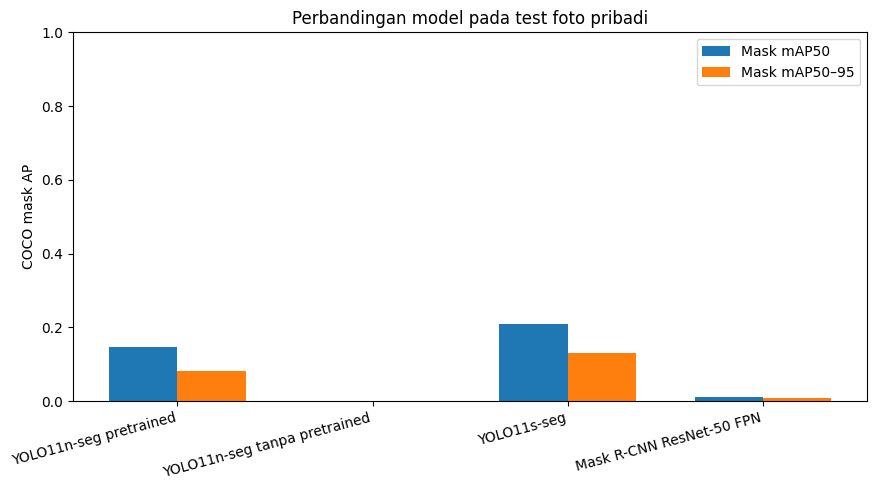

ZIP hasil: /kaggle/working/instance_segmentation_evaluation.zip
Folder siap diunduh: /kaggle/working/instance_segmentation_evaluation


In [21]:
fig,ax=plt.subplots(figsize=(9,5)); x=np.arange(len(summary)); w=0.35
ax.bar(x-w/2,summary['mask_mAP50'],w,label='Mask mAP50')
ax.bar(x+w/2,summary['mask_mAP50_95'],w,label='Mask mAP50–95')
ax.set_xticks(x,summary['model'],rotation=15,ha='right'); ax.set_ylim(0,1); ax.set_ylabel('COCO mask AP')
ax.set_title('Perbandingan model pada test foto pribadi'); ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR/'own_test_model_comparison.png',dpi=180); plt.show()
run_info={'dataset':'Roboflow indoor own photos, COCO Segmentation','own_test_images':len(image_info),'ground_truth_instances':len(annotation_rows),'classes':[c['name'] for c in gt.loadCats(cat_ids)],'models':{name:str(path) for name,path in MODEL_PATHS.items()},'inference_device':torch.cuda.get_device_name(0),'imgsz':640,'prediction_confidence_threshold':0.001,'max_detections_per_image':100,'experiment_variable':EXPERIMENT_VARIABLE,'experiment_value':EXPERIMENT_VALUE,'note':'All own photos are held-out test images; do not use them to train these models.'}
(OUT_DIR/'run_info.json').write_text(json.dumps(run_info,indent=2))
readme='\n'.join(['OUTPUT EVALUASI FOTO INDOOR PRIBADI','', 'photo_metadata_template.csv: dimensi, informasi EXIF tersedia, dan kolom kondisi untuk dilengkapi.','own_test_metrics.csv: Mask mAP50, mAP50-95, mAP75 dan AP ukuran per model.','per_class_mask_ap.csv: AP mask per kelas.','domain_shift_comparison.csv/png: Panoptic test dibanding foto pribadi (isi metrik Panoptic agar grafik muncul).','failure_cases_ranked.csv: ranking kesalahan per foto.','failure_cases_contact_sheet.png dan failure_cases/: overlay untuk lima contoh terburuk per model.','inference_time.csv: waktu inferensi.','*_predictions.json: prediksi mask format COCO.','run_info.json: konfigurasi dan informasi data.','','Overlay membantu analisis; cocokkan kasus dengan anotasi asli.'])
(OUT_DIR/'README_OUTPUT.txt').write_text(readme)
ZIP_PATH=WORK_ROOT/'instance_segmentation_evaluation.zip'
if ZIP_PATH.exists(): ZIP_PATH.unlink()
shutil.make_archive(str(ZIP_PATH.with_suffix('')),'zip',root_dir=OUT_DIR)
print('ZIP hasil:',ZIP_PATH)
print('Folder siap diunduh:',OUT_DIR)

## Apa yang dilaporkan

- `own_test_metrics.csv`: perbandingan utama tiga model pada 40 foto.
- `domain_shift_comparison.csv`: angka test Panoptic dan foto sendiri; delta negatif menunjukkan performa turun pada foto pribadi. Jelaskan perbedaan cahaya, sudut kamera, latar, dan objek yang tampak pada foto.
- `failure_cases_ranked.csv` dan folder `failure_cases/`: gunakan untuk memilih lima studi kasus dan jelaskan penyebabnya. Hijau = mask anotasi, magenta = mask prediksi; verifikasi kembali anotasi aslinya.
- Isi variabel eksperimen sesuai pemetaan NRP pada Slide Week 10 sebelum menjalankan.
- Unduh `instance_segmentation_evaluation.zip` dari panel Output Kaggle. Simpan juga checkpoint, `results.csv`, dan `test_metrics.txt` training sebagai bukti proses.
